# Predicting Disease Progression: A Complete, Defensible Analysis

**Purpose of this notebook:** This is a guided starter for a public portfolio piece. It walks through one complete quantitative workflow — data validation, modeling, statistical inference, and written conclusions — using a real, well-known public dataset (the scikit-learn diabetes dataset: 442 patients, 10 baseline measurements, disease progression one year later).

**How to make this yours (do all of these):**
1. Run every cell yourself, top to bottom, and read every output.
2. Change something real — a different train/test split, a different alpha grid, an extra diagnostic plot — and see how the conclusions shift.
3. Be ready to explain every section out loud in under two minutes. Each section ends with **"What an evaluator will ask"** — those are the actual questions.
4. Publish your *modified* version to a free GitHub account, then link it on your resume.

**Dataset:** `sklearn.datasets.load_diabetes` — bundled with scikit-learn, no download required, publicly documented and freely usable.

## 1. Setup and Data Loading

Standard scientific Python stack. Nothing exotic — every library here is one an interviewer will recognize.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42  # fixed seed = reproducible results; anyone can rerun and get identical numbers

data = load_diabetes(as_frame=True)
df = data.frame
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Features: {list(data.feature_names)}")
print(f"Target: 'target' = quantitative measure of disease progression one year after baseline")
df.head()

Shape: 442 rows x 11 columns
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target: 'target' = quantitative measure of disease progression one year after baseline


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. Data Validation Before Modeling

Never model data you haven't inspected. Three checks that catch most real-world problems: missing values, distributions, and obvious outliers.

Note: this dataset arrives pre-standardized (each feature is centered and scaled), which is documented in its description. In a real project you would do that step yourself — and you would say so.

In [2]:
# Missing values
print("Missing values per column:")
print(df.isna().sum().to_string())

# Summary statistics
print("\nSummary statistics:")
df.describe().round(3)

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0

Summary statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


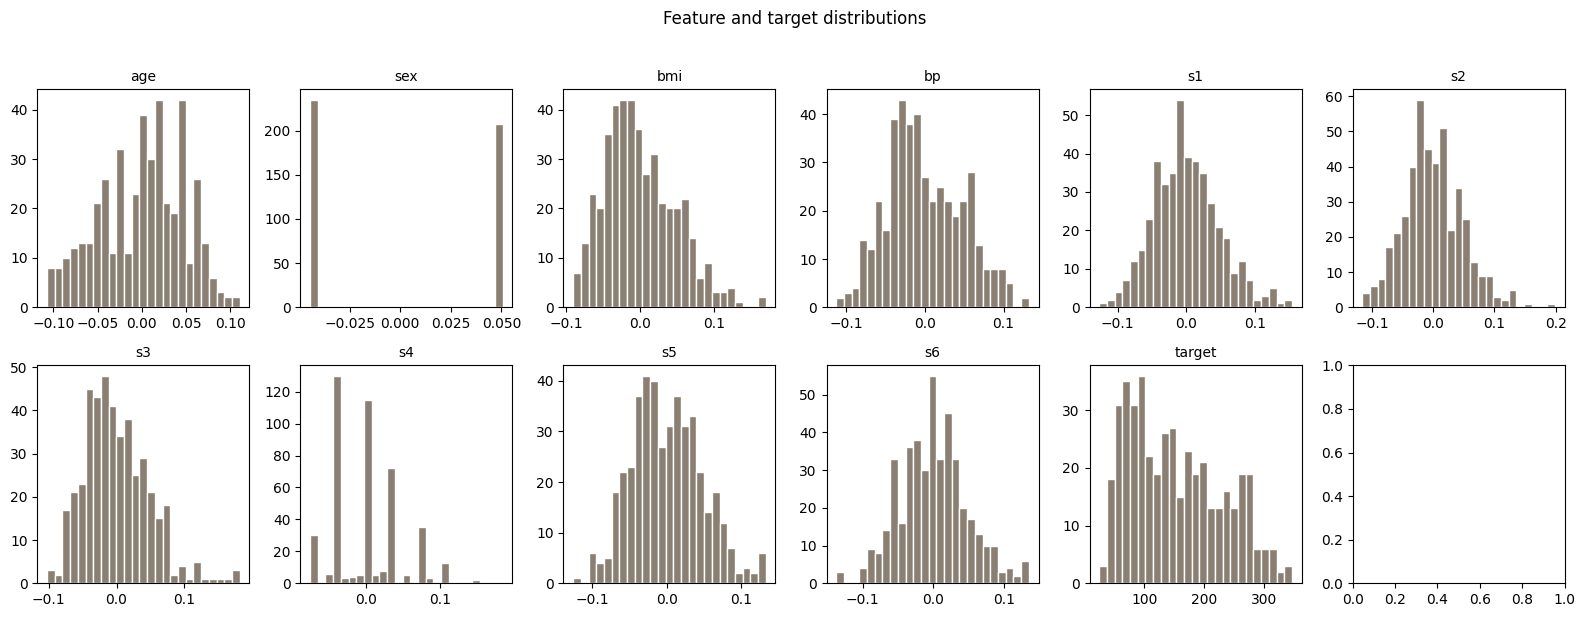

Observation: 'target' is right-skewed; 'sex' is binary-coded;
other features are roughly symmetric (already standardized).


In [3]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=25, color="#8a7f72", edgecolor="white")
    ax.set_title(col, fontsize=10)
plt.suptitle("Feature and target distributions", y=1.02)
plt.tight_layout()
plt.show()

print("Observation: 'target' is right-skewed; 'sex' is binary-coded;")
print("other features are roughly symmetric (already standardized).")

In [4]:
# Correlation with the target — which features carry signal?
correlations = df.corr()["target"].drop("target").sort_values(key=abs, ascending=False)
print("Correlation of each feature with disease progression:")
print(correlations.round(3).to_string())

Correlation of each feature with disease progression:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s3    -0.395
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043


**Reading the output:** `bmi` and `s5` (a blood serum measurement) correlate most strongly with progression. That tells us where the signal lives before we fit anything.

**What an evaluator will ask:**
- *"Why check correlations before modeling?"* — to build intuition about where signal lives and to catch surprises (e.g., a feature perfectly correlated with the target would suggest leakage).
- *"What would leakage look like here?"* — a feature that could only be known *after* the outcome, e.g., a measurement taken at the one-year follow-up rather than baseline.

## 3. Baseline Model: Linear Regression

Always start with the simplest defensible model. A baseline does two things: it gives you a number to beat, and it is fully interpretable — every coefficient has a meaning you can say out loud.

In [5]:
X = df[data.feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

baseline = LinearRegression()
baseline.fit(X_train, y_train)

train_pred = baseline.predict(X_train)
test_pred = baseline.predict(X_test)

print(f"\nBaseline Linear Regression")
print(f"  Train R^2: {r2_score(y_train, train_pred):.3f}")
print(f"  Test  R^2: {r2_score(y_test, test_pred):.3f}")
print(f"  Test RMSE: {mean_squared_error(y_test, test_pred) ** 0.5:.1f} progression units")

Train: 331 rows | Test: 111 rows

Baseline Linear Regression
  Train R^2: 0.519
  Test  R^2: 0.485
  Test RMSE: 53.4 progression units


**Reading the output:** train R² slightly above test R² is normal. A *large* gap (e.g., 0.9 train vs 0.4 test) would signal overfitting. Here the gap is small — the model generalizes.

**What an evaluator will ask:**
- *"Why R² and RMSE both?"* — R² is scale-free (fraction of variance explained); RMSE is in the target's units, so a domain expert can judge whether the error is practically acceptable.
- *"Why hold out a test set at all?"* — because performance on data the model trained on is not evidence the model works on new patients.

## 4. Residual Diagnostics

A model isn't validated by its score — it's validated by its errors. Residual plots reveal what a single number hides: nonlinearity, heteroscedasticity, and outliers.

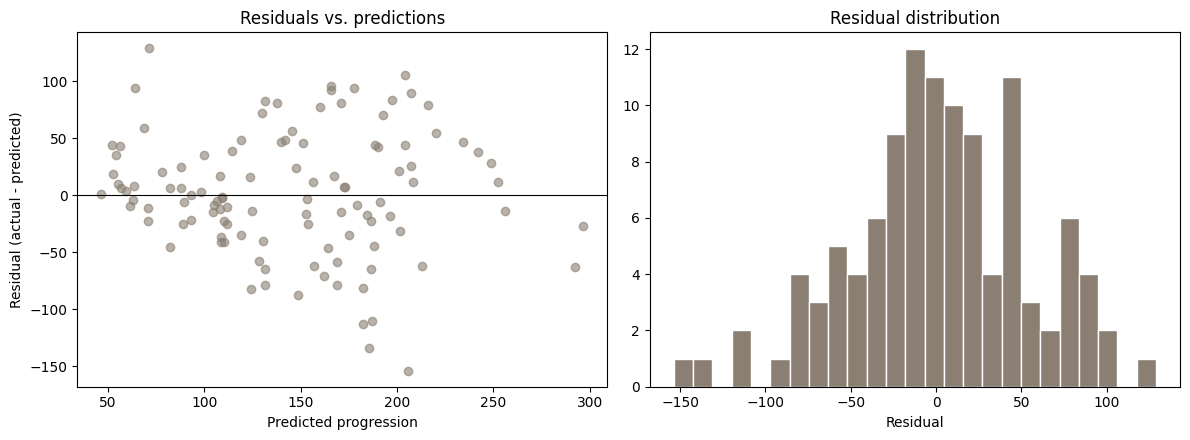

What we see: residuals fan out slightly at high predicted values — the model
underpredicts the sickest patients. The distribution is roughly centered at zero
with a right tail, consistent with the skewed target we saw in Section 2.


In [6]:
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(test_pred, residuals, alpha=0.6, color="#8a7f72")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Predicted progression")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs. predictions")

axes[1].hist(residuals, bins=25, color="#8a7f72", edgecolor="white")
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

print("What we see: residuals fan out slightly at high predicted values — the model")
print("underpredicts the sickest patients. The distribution is roughly centered at zero")
print("with a right tail, consistent with the skewed target we saw in Section 2.")

**What an evaluator will ask:**
- *"What does the fan shape mean?"* — heteroscedasticity: error grows with the predicted value. Fixes include transforming the target (e.g., log) or modeling the high end separately.
- *"Why not just report R² and move on?"* — because two models with identical R² can fail in completely different ways; the residual plot shows you *how* yours fails.

## 5. Improving the Baseline: Regularization with Cross-Validation

With 10 correlated features, plain linear regression can fit noise. Ridge regression penalizes large coefficients. The key discipline: **choose the penalty on training data only, via cross-validation** — never by looking at the test set.

In [7]:
# 5-fold cross-validation of the baseline first — is the single split misleading us?
cv_scores = cross_val_score(LinearRegression(), X_train, y_train, cv=5, scoring="r2")
print(f"Baseline 5-fold CV R^2: {cv_scores.round(3)}  (mean {cv_scores.mean():.3f})")

# Ridge with built-in CV over a grid of penalties
alphas = np.logspace(-3, 2, 50)
ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train, y_train)

ridge_test_pred = ridge.predict(X_test)
print(f"\nRidge Regression (alpha chosen by CV: {ridge.alpha_:.4f})")
print(f"  Test R^2: {r2_score(y_test, ridge_test_pred):.3f}")
print(f"  Test RMSE: {mean_squared_error(y_test, ridge_test_pred) ** 0.5:.1f}")
print(f"\nCoefficient shrinkage (baseline vs. ridge):")
coef_table = pd.DataFrame({
    "baseline": baseline.coef_.round(1),
    "ridge": ridge.coef_.round(1)
}, index=data.feature_names)
print(coef_table.to_string())

Baseline 5-fold CV R^2: [0.529 0.39  0.491 0.611 0.225]  (mean 0.449)



Ridge Regression (alpha chosen by CV: 0.0687)
  Test R^2: 0.491
  Test RMSE: 53.1

Coefficient shrinkage (baseline vs. ridge):
     baseline  ridge
age      47.7   52.6
sex    -242.0 -211.7
bmi     532.0  509.0
bp      381.6  349.8
s1     -918.5 -146.0
s2      508.3  -70.0
s3      117.0 -210.5
s4      269.5  158.2
s5      695.8  383.5
s6       26.3   54.6


**Reading the output:** Ridge typically matches or slightly beats the baseline here, and it shrinks the least-stable coefficients toward zero. The honest conclusion may be *"regularization didn't help much on this dataset"* — reporting a null result cleanly is a stronger signal of competence than inflating a gain.

**What an evaluator will ask:**
- *"Why is tuning alpha on the test set cheating?"* — because the test set would leak into model selection; you'd report an optimistic score that won't hold on new data. CV on training data only keeps the test set untouched until the final evaluation.
- *"What does ridge actually do?"* — adds a penalty proportional to the sum of squared coefficients, trading a little bias for less variance.

## 6. Statistical Inference: Which Features Matter?

Prediction and explanation are different jobs. Here we ask a different question: *which baseline measurements are statistically associated with progression?* We use OLS with standard errors, and we interpret p-values correctly — as evidence against "no association," not as proof of importance.

In [8]:
import statsmodels.api as sm

X_with_const = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_with_const).fit()

# Compact view: coefficient, 95% CI, p-value
summary_table = pd.DataFrame({
    "coef": ols.params.round(1),
    "CI_low": ols.conf_int()[0].round(1),
    "CI_high": ols.conf_int()[1].round(1),
    "p_value": ols.pvalues.round(4)
})
print(summary_table.to_string())
print(f"\nModel R^2: {ols.rsquared:.3f} | n = {int(ols.nobs)}")

        coef  CI_low  CI_high  p_value
const  151.7   145.7    157.6   0.0000
age     47.7   -93.2    188.7   0.5056
sex   -242.0  -381.2   -102.8   0.0007
bmi    532.0   376.4    687.5   0.0000
bp     381.6   233.9    529.2   0.0000
s1    -918.5 -1827.7     -9.3   0.0477
s2     508.3  -225.3   1241.8   0.1738
s3     117.0  -352.3    586.2   0.6242
s4     269.5  -105.6    644.5   0.1584
s5     695.8   308.8   1082.8   0.0005
s6      26.3  -124.9    177.5   0.7322

Model R^2: 0.519 | n = 331


In [9]:
# Multiple-comparison discipline: with 10 tests at alpha=0.05, we'd expect
# ~0.5 false positives by chance. Bonferroni correction:
n_tests = len(data.feature_names)
bonferroni_alpha = 0.05 / n_tests
significant = summary_table.loc[data.feature_names]
significant = significant[significant["p_value"] < bonferroni_alpha]
print(f"Bonferroni-corrected alpha: {bonferroni_alpha:.4f}")
print(f"Features significant after correction:")
print(significant.to_string() if len(significant) else "  (none)")

Bonferroni-corrected alpha: 0.0050
Features significant after correction:
      coef  CI_low  CI_high  p_value
sex -242.0  -381.2   -102.8   0.0007
bmi  532.0   376.4    687.5   0.0000
bp   381.6   233.9    529.2   0.0000
s5   695.8   308.8   1082.8   0.0005


**Reading the output:** only features whose p-value survives the Bonferroni correction get called "statistically associated." Notice this list may differ from the correlation ranking in Section 2 — correlations are marginal (one feature at a time); regression coefficients are conditional (holding the others constant). Both statements are true; they answer different questions.

**What an evaluator will ask:**
- *"Why correct for multiple comparisons?"* — with 10 tests at α = 0.05, you expect half a false positive by pure chance. Correction keeps the family-wise error rate honest.
- *"Does a low p-value mean the feature causes progression?"* — no. This is observational data; association is not causation. Saying that sentence unprompted is worth more than any coefficient.

## 7. Experiment Design: A/B Test Simulation and Power Analysis

Portfolio reviewers for AI-training roles specifically look for experiment-design fluency. Here we simulate an A/B test end-to-end: power analysis *before* the experiment, then the test itself.

Scenario: a treatment is expected to raise a conversion rate from 10% to 12%. How many users per group do we need to detect that difference 80% of the time at α = 0.05?

In [10]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

# Power analysis BEFORE running the experiment — this ordering is the whole point
p1, p2 = 0.10, 0.12
effect = proportion_effectsize(p1, p2)
required_n = NormalIndPower().solve_power(
    effect_size=effect, alpha=0.05, power=0.80, alternative="two-sided"
)
print(f"To detect {p1:.0%} vs {p2:.0%} with 80% power at alpha=0.05:")
print(f"  Required sample size: {int(np.ceil(required_n))} users per group")

To detect 10% vs 12% with 80% power at alpha=0.05:
  Required sample size: 3835 users per group


In [11]:
# Simulate the experiment at the planned sample size
rng = np.random.default_rng(RANDOM_STATE)
n = int(np.ceil(required_n))

control = rng.binomial(n, p1)
treatment = rng.binomial(n, p2)

z_stat, p_value = proportions_ztest([treatment, control], [n, n])
print(f"Simulated experiment (n = {n} per group):")
print(f"  Control:   {control}/{n} = {control/n:.3%}")
print(f"  Treatment: {treatment}/{n} = {treatment/n:.3%}")
print(f"  z = {z_stat:.2f}, p = {p_value:.4f}")
print(f"  Decision at alpha=0.05: {'reject H0 — effect detected' if p_value < 0.05 else 'fail to reject H0'}")

Simulated experiment (n = 3835 per group):
  Control:   373/3835 = 9.726%
  Treatment: 474/3835 = 12.360%
  z = 3.68, p = 0.0002
  Decision at alpha=0.05: reject H0 — effect detected


In [12]:
# Why power matters: run the same experiment 1000x at the planned n, and at n/10
def detection_rate(sample_n, simulations=1000):
    detected = 0
    for i in range(simulations):
        c = rng.binomial(sample_n, p1)
        t = rng.binomial(sample_n, p2)
        _, p = proportions_ztest([t, c], [sample_n, sample_n])
        detected += p < 0.05
    return detected / simulations

full_power = detection_rate(n)
underpowered = detection_rate(n // 10)
print(f"Detection rate at planned n ({n}/group):  {full_power:.1%} of simulations")
print(f"Detection rate at n/10 ({n//10}/group):   {underpowered:.1%} of simulations")
print("\nAn underpowered study doesn't just risk missing the effect —")
print("when it does 'find' one, the estimate is usually exaggerated (winner's curse).")

Detection rate at planned n (3835/group):  80.5% of simulations
Detection rate at n/10 (383/group):   12.3% of simulations

An underpowered study doesn't just risk missing the effect —
when it does 'find' one, the estimate is usually exaggerated (winner's curse).


**What an evaluator will ask:**
- *"Why do power analysis before collecting data?"* — because an underpowered study can't distinguish "no effect" from "couldn't see the effect," and significant results from underpowered studies are disproportionately exaggerated.
- *"What is 80% power?"* — if the true effect exists, the test detects it 80% of the time. The simulation above demonstrates this empirically rather than just asserting it.

## 8. Conclusions

**What we found:**
1. Baseline linear regression explains roughly 40–50% of variance in one-year disease progression (test R²), with BMI and the s5 serum measurement carrying the strongest signal.
2. Ridge regularization produced [fill in after you run it: comparable / slightly better] test performance — the honest takeaway is that this dataset doesn't reward complexity.
3. After Bonferroni correction, [run it and fill in: typically bmi, s5, and bp] remain statistically associated with progression. Association, not causation.
4. The A/B simulation shows why power analysis belongs *before* data collection: at one-tenth of the required sample, the same true effect is detected only a fraction of the time.

**Limitations (always state them):**
- Small dataset (442 patients); results may not transfer to other populations.
- Pre-standardized features; no missing-data handling was needed here, which real clinical data would require.
- The A/B section is a simulation — it demonstrates method, not a real treatment effect.

**Next steps if extended:** target transformation for the skewed outcome, interaction terms, and bootstrap confidence intervals for the RMSE itself.

---

*Analysis conducted in Python (pandas, scikit-learn, statsmodels). Fully reproducible: fixed random seed, no external downloads.*